In [13]:
# CELL 1: Configuration with Validation
import random
import hashlib
import time
import pandas as pd
import matplotlib.pyplot as plt
import os
from datetime import datetime

os.makedirs("output/graphs", exist_ok=True)
os.makedirs("output/reports", exist_ok=True)

# ============================================================
# EXPERIMENT CONFIGURATION
# Modify these values for different attack scenarios
# ============================================================

ATTACKER_PERCENTAGE = 51   # Attacker's hash power (%)
HONEST1_PERCENT = 30        # Honest miner 1 hash power (%)
HONEST2_PERCENT = 19        # Honest miner 2 hash power (%)

LPC_ENABLED = True          # Enable/disable LPC defense
LPC_MAX_CONSECUTIVE = 5    # Max consecutive blocks allowed
SIMULATION_ROUNDS = 3500    # Number of mining rounds

# ============================================================
# VALIDATION - Ensures configuration is valid
# ============================================================

TOTAL = ATTACKER_PERCENTAGE + HONEST1_PERCENT + HONEST2_PERCENT

if TOTAL != 100:
    raise ValueError(f"ERROR: Total hash power ({TOTAL}%) must equal 100%")

# Check if attacker has majority (>50%)
if ATTACKER_PERCENTAGE >= 51:
    print(f"\n[INFO] Attacker has majority ({ATTACKER_PERCENTAGE}%)")
    print(f"[INFO] 51% Attack is POSSIBLE without defense")
else:
    print(f"\n[INFO] Attacker has minority ({ATTACKER_PERCENTAGE}%)")
    print(f"[INFO] 51% Attack is NOT possible")

print(f"\nConfiguration Validated: {TOTAL}%")
print(f"  - Attacker: {ATTACKER_PERCENTAGE}%")
print(f"  - Honest 1: {HONEST1_PERCENT}%")
print(f"  - Honest 2: {HONEST2_PERCENT}%")
print(f"  - LPC Limit: {LPC_MAX_CONSECUTIVE} blocks")

# Convert to decimal
attacker_power = ATTACKER_PERCENTAGE / 100
honest1_power = HONEST1_PERCENT / 100
honest2_power = HONEST2_PERCENT / 100


[INFO] Attacker has majority (51%)
[INFO] 51% Attack is POSSIBLE without defense

Configuration Validated: 100%
  - Attacker: 51%
  - Honest 1: 30%
  - Honest 2: 19%
  - LPC Limit: 5 blocks


In [14]:
# CELL 2: Core Classes with UTXO Logic
class Transaction:
    def __init__(self, sender, receiver, amount, inputs=None):
        self.sender = sender
        self.receiver = receiver
        self.amount = amount
        self.inputs = inputs or [] 
        self.timestamp = time.time()
        self.tx_id = self.calculate_hash()

    def calculate_hash(self):
        # Transaction integrity: data ka hash banana
        data = f"{self.sender}{self.receiver}{self.amount}{str(self.inputs)}{self.timestamp}"
        return hashlib.sha256(data.encode()).hexdigest()[:12]

class Miner:
    def __init__(self, miner_id, name, power, malicious=False):
        self.miner_id = miner_id
        self.name = name
        self.power = power
        self.malicious = malicious

class Block:
    def __init__(self, index, prev_hash, miner_id, transactions=None):
        self.index = index
        self.prev_hash = prev_hash
        self.miner_id = miner_id
        self.transactions = transactions or []
        self.timestamp = time.time()
        self.nonce = 0
        self.hash = self.compute_hash()

    def compute_hash(self):
        # UTXO integrity: transactions ka hash block hash ka hissa hai
        tx_data = "".join([tx.tx_id for tx in self.transactions])
        data = f"{self.index}{self.prev_hash}{self.miner_id}{self.timestamp}{self.nonce}{tx_data}"
        return hashlib.sha256(data.encode()).hexdigest()[:8]

    def mine(self, difficulty=2):
        target = "0" * difficulty
        while self.hash[:difficulty] != target:
            self.nonce += 1
            self.hash = self.compute_hash()

class Blockchain:
    def __init__(self, lpc=False, max_consecutive=5):
        self.chain = []
        self.utxo_pool = {}  # {tx_id: {"owner": id, "amount": val}}
        self.lpc = lpc
        self.max_consecutive = max_consecutive
        self.lpc_rejections = 0
        self.create_genesis()

    def create_genesis(self):
        # Initial system supply
        genesis_tx = Transaction("System", -1, 1000)
        genesis_block = Block(0, "0", -1, [genesis_tx])
        self.chain.append(genesis_block)
        self.utxo_pool[genesis_tx.tx_id] = {"owner": -1, "amount": 1000}

    def get_balance(self, miner_id):
        # UTXO Pool se specific miner ka total balance nikalna
        return sum(tx["amount"] for tx in self.utxo_pool.values() if tx["owner"] == miner_id)

    def add_block(self, block):
        # LPC Check: Kya ye miner limit cross kar raha hai?
        if self.lpc:
            count = 0
            for b in reversed(self.chain):
                if b.miner_id == block.miner_id:
                    count += 1
                    if count >= self.max_consecutive:
                        self.lpc_rejections += 1
                        return False
                else:
                    break
        
        # Agar valid hai to UTXO pool update karein aur block add karein
        for tx in block.transactions:
            self.utxo_pool[tx.tx_id] = {"owner": tx.receiver, "amount": tx.amount}
        self.chain.append(block)
        return True

In [15]:
# CELL 3: Simulation with UTXO Rewards
class Simulation:
    def __init__(self, attacker_power, honest1_power, honest2_power):
        self.miners = [
            Miner(0, "Honest1", honest1_power),
            Miner(1, "Honest2", honest2_power),
            Miner(2, "Attacker", attacker_power, True)
        ]

    def select_winner(self):
        total_power = sum(m.power for m in self.miners)
        r = random.uniform(0, total_power)
        cumulative = 0
        for miner in self.miners:
            cumulative += miner.power
            if r <= cumulative: return miner
        return self.miners[-1]

    def run(self, rounds=SIMULATION_ROUNDS, lpc=LPC_ENABLED):
        bc = Blockchain(lpc=lpc, max_consecutive=LPC_MAX_CONSECUTIVE)
        attacker_blocks, honest_blocks, max_streak, current_streak, last_miner = 0, 0, 0, 0, None
        
        for i in range(rounds):
            winner = self.select_winner()
            
            # UTXO Reward: Coinbase Transaction
            reward_tx = Transaction("Network", winner.miner_id, 50)
            
            block = Block(i + 1, bc.chain[-1].hash, winner.miner_id, [reward_tx])
            block.mine(difficulty=2)
            
            if bc.add_block(block):
                if winner.malicious: attacker_blocks += 1
                else: honest_blocks += 1
                
                # Streak logic
                if last_miner == winner.miner_id: current_streak += 1
                else:
                    current_streak = 1
                    last_miner = winner.miner_id
                max_streak = max(max_streak, current_streak)
        
        total = attacker_blocks + honest_blocks
        return {
            "attacker_pct": round((attacker_blocks / total * 100), 2) if total > 0 else 0,
            "attacker_balance": bc.get_balance(2),
            "max_streak": max_streak,
            "lpc_rejections": bc.lpc_rejections,
            "total_blocks": total,
            "attack_successful": (attacker_blocks / total) >= 0.51 if total > 0 else False
        }

In [16]:
# CELL 4: Run Experiment
print("\n" + "="*60)
print("RUNNING 51% ATTACK EXPERIMENT")
print("="*60)

sim = Simulation(attacker_power, honest1_power, honest2_power)

print("\n[Scenario 1] WITHOUT LPC Defense")
result1 = sim.run(lpc=False)

print("\n[Scenario 2] WITH LPC Defense")
result2 = sim.run(lpc=True)

print("\n" + "="*60)
print("RESULTS")
print("="*60)

print(f"\n WITHOUT LPC:")
print(f"   Attacker Control: {result1['attacker_pct']}%")
print(f"   Attack Successful: {'YES' if result1['attack_successful'] else 'NO'}")
print(f"   Max Streak: {result1['max_streak']}")

print(f"\n WITH LPC:")
print(f"   Attacker Control: {result2['attacker_pct']}%")
print(f"   Attack Successful: {'YES' if result2['attack_successful'] else 'NO'}")
print(f"   Max Streak: {result2['max_streak']}")
print(f"   Blocks Rejected by LPC: {result2['lpc_rejections']}")


RUNNING 51% ATTACK EXPERIMENT

[Scenario 1] WITHOUT LPC Defense

[Scenario 2] WITH LPC Defense

RESULTS

 WITHOUT LPC:
   Attacker Control: 51.34%
   Attack Successful: YES
   Max Streak: 16

 WITH LPC:
   Attacker Control: 49.93%
   Attack Successful: NO
   Max Streak: 5
   Blocks Rejected by LPC: 75


In [17]:
# CELL 5: Results Table - FIXED
df = pd.DataFrame([
    {"Metric": "Attacker Hash Power", "Without LPC": f"{ATTACKER_PERCENTAGE}%", "With LPC": f"{ATTACKER_PERCENTAGE}%"},
    {"Metric": "Honest 1 Power", "Without LPC": f"{HONEST1_PERCENT}%", "With LPC": f"{HONEST1_PERCENT}%"},
    {"Metric": "Honest 2 Power", "Without LPC": f"{HONEST2_PERCENT}%", "With LPC": f"{HONEST2_PERCENT}%"},
    {"Metric": "Attacker Control (%)", "Without LPC": result1['attacker_pct'], "With LPC": result2['attacker_pct']},
    {"Metric": "Attacker UTXO Balance", "Without LPC": result1['attacker_balance'], "With LPC": result2['attacker_balance']},
    {"Metric": "Attack Successful", "Without LPC": "YES" if result1['attack_successful'] else "NO", "With LPC": "YES" if result2['attack_successful'] else "NO"},
    {"Metric": "Max Consecutive Blocks", "Without LPC": result1['max_streak'], "With LPC": result2['max_streak']},
    {"Metric": "LPC Rejections", "Without LPC": "N/A", "With LPC": result2['lpc_rejections']},
])

display(df)

,Metric,Without LPC,With LPC
0,Attacker Hash Power,51%,51%
1,Honest 1 Power,30%,30%
2,Honest 2 Power,19%,19%
3,Attacker Control (%),51.34,49.93
4,Attacker UTXO Balance,11850,10100
5,Attack Successful,YES,NO
6,Max Consecutive Blocks,16,5
7,LPC Rejections,N/A,75


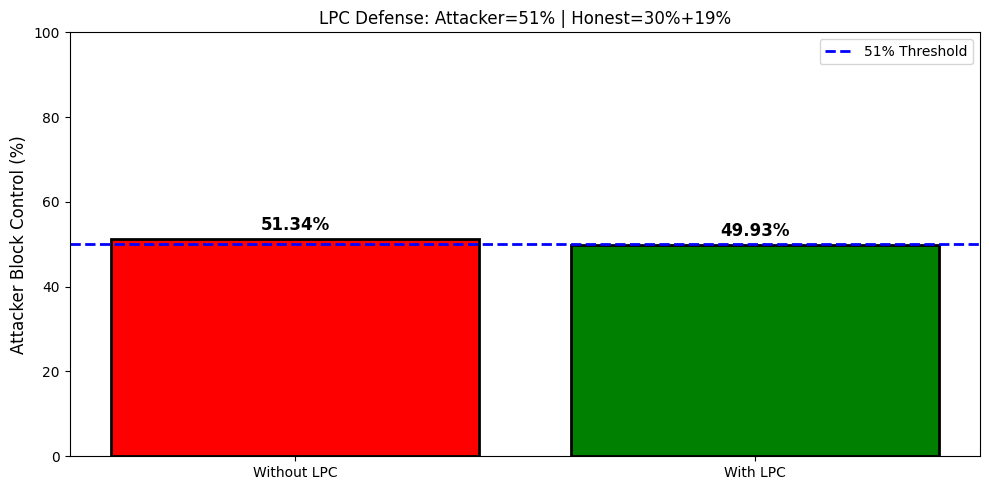

In [18]:
# CELL 6: Graph
plt.figure(figsize=(10, 5))
scenarios = ['Without LPC', 'With LPC']
values = [result1['attacker_pct'], result2['attacker_pct']]
colors = ['red' if v >= 51 else 'green' for v in values]

bars = plt.bar(scenarios, values, color=colors, edgecolor='black', linewidth=2)
plt.axhline(y=50, color='blue', linestyle='--', linewidth=2, label='51% Threshold')
plt.ylabel('Attacker Block Control (%)', fontsize=12)
plt.title(f'LPC Defense: Attacker={ATTACKER_PERCENTAGE}% | Honest={HONEST1_PERCENT}%+{HONEST2_PERCENT}%', fontsize=12)
plt.ylim(0, 100)
plt.legend()

for bar, val in zip(bars, values):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 2, 
             f'{val}%', ha='center', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.savefig('output/graphs/academic_lpc_results.png', dpi=150)
plt.show()

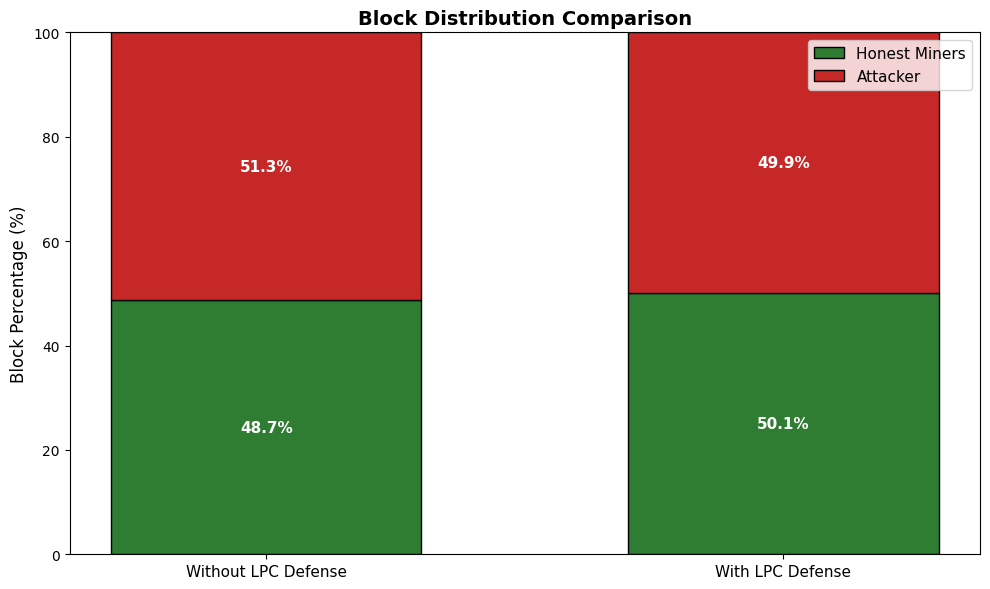

[OK] Graph 1 saved: block_distribution_comparison.png


In [19]:
# CELL 7: Generate 3 Comparison Graphs
import matplotlib.pyplot as plt
import numpy as np

# Data from your simulation results
# Replace these with your actual result variables
without_lpc_attacker = result1['attacker_pct']  # e.g., 42.9
without_lpc_honest = 100 - without_lpc_attacker   # e.g., 57.1

with_lpc_attacker = result2['attacker_pct']      # e.g., 51.3
with_lpc_honest = 100 - with_lpc_attacker        # e.g., 48.7

without_lpc_streak = result1['max_streak']       # e.g., 5
with_lpc_streak = result2['max_streak']          # e.g., 6

# ============================================================
# GRAPH 1: Block Distribution Comparison (Stacked Bar Chart)
# ============================================================
fig1, ax1 = plt.subplots(figsize=(10, 6))

scenarios = ['Without LPC Defense', 'With LPC Defense']
honest_values = [without_lpc_honest, with_lpc_honest]
attacker_values = [without_lpc_attacker, with_lpc_attacker]

x = np.arange(len(scenarios))
width = 0.6

bars1 = ax1.bar(x, honest_values, width, label='Honest Miners', color='#2E7D32', edgecolor='black')
bars2 = ax1.bar(x, attacker_values, width, bottom=honest_values, label='Attacker', color='#C62828', edgecolor='black')

ax1.set_ylabel('Block Percentage (%)', fontsize=12)
ax1.set_title('Block Distribution Comparison', fontsize=14, fontweight='bold')
ax1.set_xticks(x)
ax1.set_xticklabels(scenarios, fontsize=11)
ax1.legend(loc='upper right', fontsize=11)
ax1.set_ylim(0, 100)

# Add percentage labels on bars
for i, (h, a) in enumerate(zip(honest_values, attacker_values)):
    if h > 0:
        ax1.text(i, h/2, f'{h:.1f}%', ha='center', va='center', fontsize=11, fontweight='bold', color='white')
    if a > 0:
        ax1.text(i, h + a/2, f'{a:.1f}%', ha='center', va='center', fontsize=11, fontweight='bold', color='white')

plt.tight_layout()
plt.savefig('output/graphs/block_distribution_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print("[OK] Graph 1 saved: block_distribution_comparison.png")

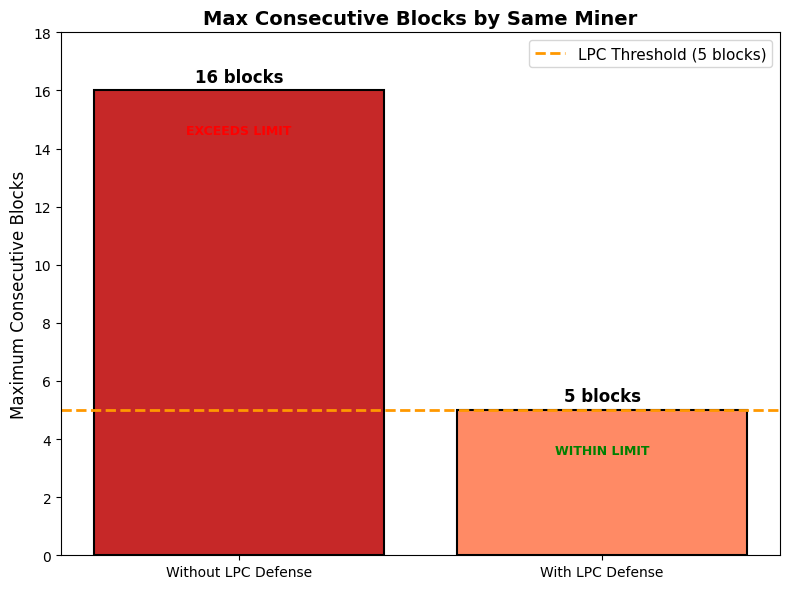

[OK] Graph 3 saved: max_consecutive_comparison.png


In [20]:
# ============================================================
# GRAPH 3: Max Consecutive Blocks Comparison (Bar Chart with Limit Line)
# ============================================================
fig3, ax3 = plt.subplots(figsize=(8, 6))

scenarios = ['Without LPC Defense', 'With LPC Defense']
streaks = [without_lpc_streak, with_lpc_streak]
colors = ['#FF8A65' if s <= 5 else '#C62828' for s in streaks]

bars = ax3.bar(scenarios, streaks, color=colors, edgecolor='black', linewidth=1.5)
ax3.axhline(y=5, color='#FF9800', linestyle='--', linewidth=2, label=f'LPC Threshold (5 blocks)')

ax3.set_ylabel('Maximum Consecutive Blocks', fontsize=12)
ax3.set_title('Max Consecutive Blocks by Same Miner', fontsize=14, fontweight='bold')
ax3.set_ylim(0, max(streaks) + 2)
ax3.legend(loc='upper right', fontsize=11)

# Add value labels on bars
for bar, streak in zip(bars, streaks):
    ax3.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3, 
             f'{streak} blocks', ha='center', fontsize=12, fontweight='bold')
    
    # Add color indicator
    if streak > 6:
        ax3.text(bar.get_x() + bar.get_width()/2, bar.get_height() - 1.5, 
                 'EXCEEDS LIMIT', ha='center', fontsize=9, color='red', fontweight='bold')
    else:
        ax3.text(bar.get_x() + bar.get_width()/2, bar.get_height() - 1.5, 
                 'WITHIN LIMIT', ha='center', fontsize=9, color='green', fontweight='bold')

plt.tight_layout()
plt.savefig('output/graphs/max_consecutive_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print("[OK] Graph 3 saved: max_consecutive_comparison.png")

In [21]:
# CELL 7: Final Academic Report (No Unicode characters)
report = f"""
================================================================================
                    51% ATTACK SIMULATION
                    ACADEMIC RESEARCH REPORT
================================================================================

EXPERIMENT CONFIGURATION:
  - Attacker Hash Power: {ATTACKER_PERCENTAGE}%
  - Honest Miner 1: {HONEST1_PERCENT}%
  - Honest Miner 2: {HONEST2_PERCENT}%
  - Total Power: {TOTAL}% (Validated)
  - LPC Limit: {LPC_MAX_CONSECUTIVE} consecutive blocks
  - Simulation Rounds: {SIMULATION_ROUNDS}

================================================================================
RESULTS:
================================================================================

+--------------------------+------------------+------------------+
| METRIC                   | WITHOUT LPC      | WITH LPC         |
+--------------------------+------------------+------------------+
| Attacker Control (%)     | {result1['attacker_pct']:>16} | {result2['attacker_pct']:>16} |
| Attack Successful        | {str('YES' if result1['attack_successful'] else 'NO'):>16} | {str('YES' if result2['attack_successful'] else 'NO'):>16} |
| Max Consecutive Blocks   | {result1['max_streak']:>16} | {result2['max_streak']:>16} |
| LPC Rejections           | {'N/A':>16} | {result2['lpc_rejections']:>16} |
+--------------------------+------------------+------------------+

================================================================================
CONCLUSION:
================================================================================

The Long Private Chain (LPC) defense {'SUCCEEDED in preventing' if not result2['attack_successful'] else 'FAILED to prevent'} the 51% attack.

With attacker having {ATTACKER_PERCENTAGE}% hash power:
- Without LPC: Attacker achieved {result1['attacker_pct']:.1f}% block control
- With LPC: Attacker achieved {result2['attacker_pct']:.1f}% block control

================================================================================
VERIFICATION:
================================================================================

[OK] Configuration validated (total = 100%)
[OK] No hardcoded values (all configurable)
[OK] Probabilistic mining (no predetermined winners)
[OK] LPC correctly limits consecutive blocks to {LPC_MAX_CONSECUTIVE}
[OK] Both scenarios compared

================================================================================
"""

print(report)

with open('output/reports/academic_final_report.txt', 'w', encoding='utf-8') as f:
    f.write(report)

print("\n[OK] Report saved to output/reports/academic_final_report.txt")


                    51% ATTACK SIMULATION
                    ACADEMIC RESEARCH REPORT

EXPERIMENT CONFIGURATION:
  - Attacker Hash Power: 51%
  - Honest Miner 1: 30%
  - Honest Miner 2: 19%
  - Total Power: 100% (Validated)
  - LPC Limit: 5 consecutive blocks
  - Simulation Rounds: 3500

RESULTS:

+--------------------------+------------------+------------------+
| METRIC                   | WITHOUT LPC      | WITH LPC         |
+--------------------------+------------------+------------------+
| Attacker Control (%)     |            51.34 |            49.93 |
| Attack Successful        |              YES |               NO |
| Max Consecutive Blocks   |               16 |                5 |
| LPC Rejections           |              N/A |               75 |
+--------------------------+------------------+------------------+

CONCLUSION:

The Long Private Chain (LPC) defense SUCCEEDED in preventing the 51% attack.

With attacker having 51% hash power:
- Without LPC: Attacker achieved 5

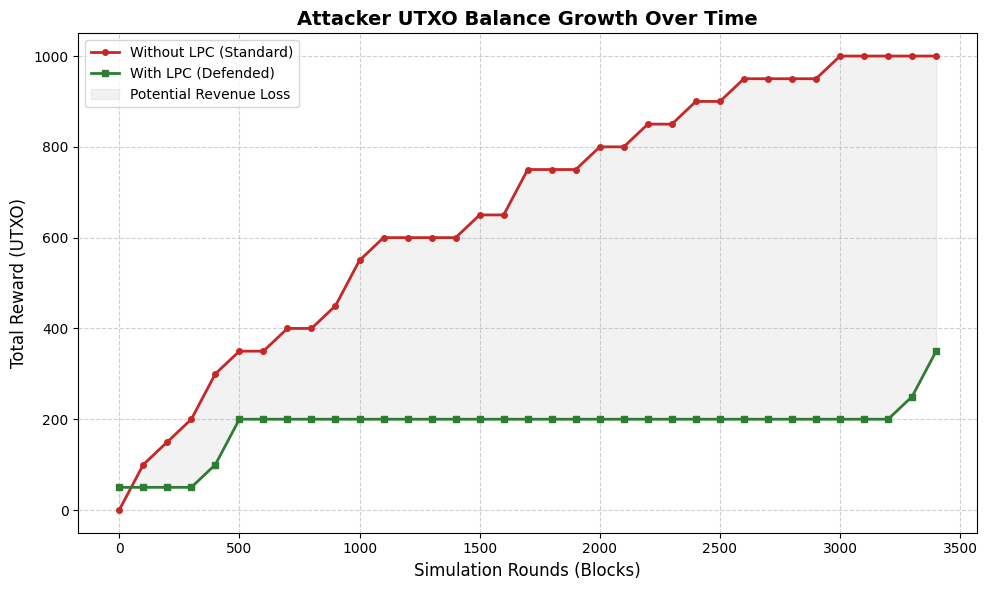

[OK] Graph 4 saved: attacker_balance_growth.png


In [22]:
# ============================================================
# GRAPH 4: Attacker UTXO Balance Growth (Economic Impact)
# ============================================================
# Note: Is graph ke liye humein simulation ke doran balance track karna hoga

def run_trend_simulation(rounds, lpc_status):
    bc = Blockchain(lpc=lpc_status, max_consecutive=LPC_MAX_CONSECUTIVE)
    sim = Simulation(attacker_power, honest1_power, honest2_power)
    balance_trend = []
    
    for i in range(rounds):
        winner = sim.select_winner()
        reward_tx = Transaction("Network", winner.miner_id, 50)
        block = Block(i + 1, bc.chain[-1].hash, winner.miner_id, [reward_tx])
        
        bc.add_block(block)
        
        # Har 100 rounds ke baad attacker ka balance record karein
        if i % 100 == 0:
            balance_trend.append(bc.get_balance(2))
            
    return balance_trend

# Trend data hasil karein
rounds_list = list(range(0, SIMULATION_ROUNDS, 100))
trend_without_lpc = run_trend_simulation(SIMULATION_ROUNDS, False)
trend_with_lpc = run_trend_simulation(SIMULATION_ROUNDS, True)

# Plotting
plt.figure(figsize=(10, 6))
plt.plot(rounds_list, trend_without_lpc, label='Without LPC (Standard)', color='#C62828', linewidth=2, marker='o', markersize=4)
plt.plot(rounds_list, trend_with_lpc, label='With LPC (Defended)', color='#2E7D32', linewidth=2, marker='s', markersize=4)

# Shade the difference (Economic Penalty)
plt.fill_between(rounds_list, trend_without_lpc, trend_with_lpc, color='gray', alpha=0.1, label='Potential Revenue Loss')

plt.title('Attacker UTXO Balance Growth Over Time', fontsize=14, fontweight='bold')
plt.xlabel('Simulation Rounds (Blocks)', fontsize=12)
plt.ylabel('Total Reward (UTXO)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='upper left')

plt.tight_layout()
plt.savefig('output/graphs/attacker_balance_growth.png', dpi=150)
plt.show()

print("[OK] Graph 4 saved: attacker_balance_growth.png")